In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
df = pd.read_csv("00 concrete_data.csv")

In [3]:
df.sample(10)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
852,298.0,0.0,107.0,186.0,6.0,879.0,815.0,28,42.64
165,425.0,106.3,0.0,151.4,18.6,936.0,803.7,91,66.70
592,382.5,0.0,0.0,185.7,0.0,1047.8,739.3,28,37.44
639,400.0,0.0,0.0,187.0,0.0,1025.0,745.0,28,43.70
244,238.1,0.0,94.1,186.7,7.0,949.9,847.0,3,19.93
588,186.2,124.1,0.0,185.7,0.0,1083.4,764.3,7,8.00
470,251.4,0.0,118.3,192.9,5.8,1043.6,754.3,100,40.15
288,181.4,0.0,167.0,169.6,7.6,1055.6,777.8,100,45.37
268,212.0,0.0,124.8,159.0,7.8,1085.4,799.5,100,47.82
917,148.0,175.0,0.0,171.0,2.0,1000.0,828.0,28,26.92


In [4]:
df.shape

(1030, 9)

In [5]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [6]:
df.dtypes

Cement                float64
Blast Furnace Slag    float64
Fly Ash               float64
Water                 float64
Superplasticizer      float64
Coarse Aggregate      float64
Fine Aggregate        float64
Age                     int64
Strength              float64
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [8]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


# Just applying LinearRegression before applying any function transformer.

# Train/Test split.

In [9]:
x = df.drop(columns = 'Strength', axis = 'columns')
y = df.drop(x, axis = 'columns')

In [10]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [11]:
from sklearn.linear_model import LinearRegression

In [12]:
lr = LinearRegression()

In [13]:
lr.fit(x_train, y_train)

LinearRegression()

In [14]:
pred = lr.predict(x_test)

In [15]:
from sklearn.metrics import r2_score

In [16]:
r2_score(pred, y_test)

0.4961797600238619

In [17]:
# Applying cross validation.

from sklearn.model_selection import cross_val_score

In [18]:
cross_val_score(estimator = lr, X = x_train, y = y_train, cv = 10, scoring = 'r2').mean()

0.5965023512592226

# Plotting distplots and QQ plots without transformers.

C:\Users\jugal\AppData\Local\Temp\ipykernel_12908\438105041.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[column])
C:\Users\jugal\AppData\Local\Temp\ipykernel_12908\438105041.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[column])
C:\Users\jugal\AppData\Local\Temp\ipyk

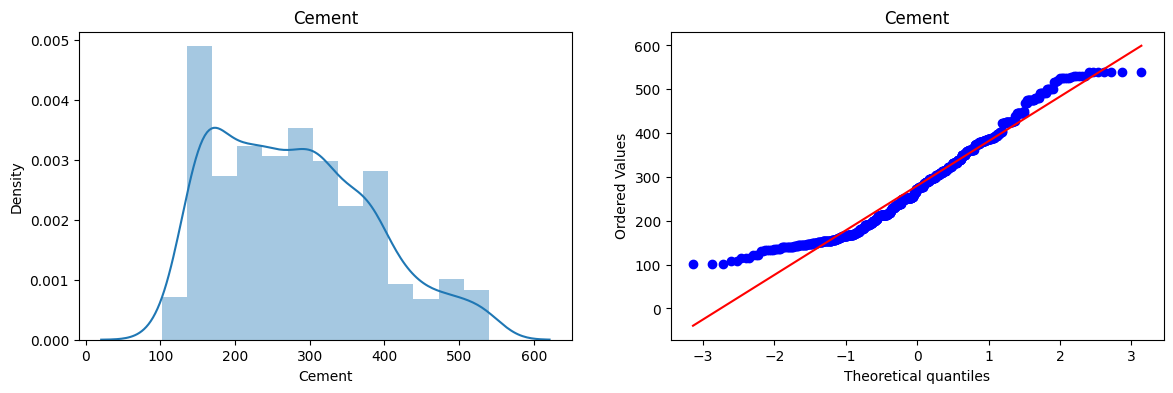

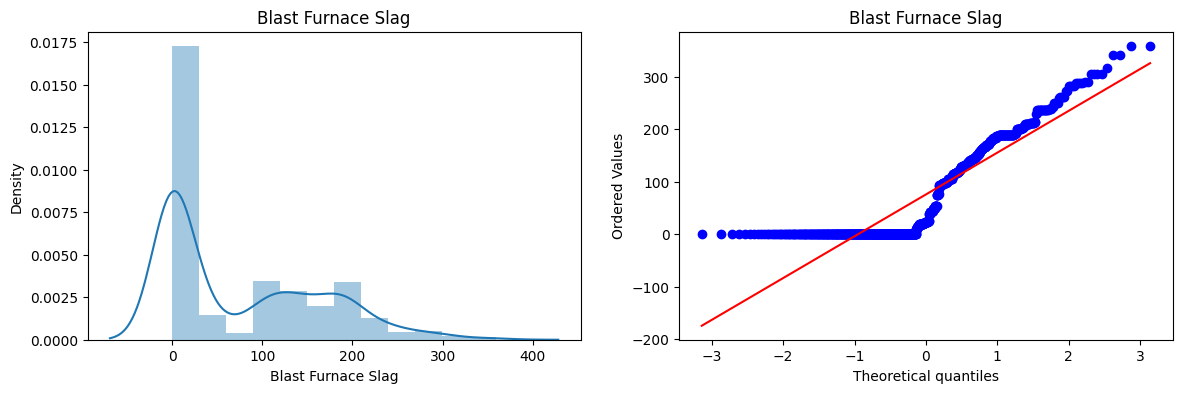

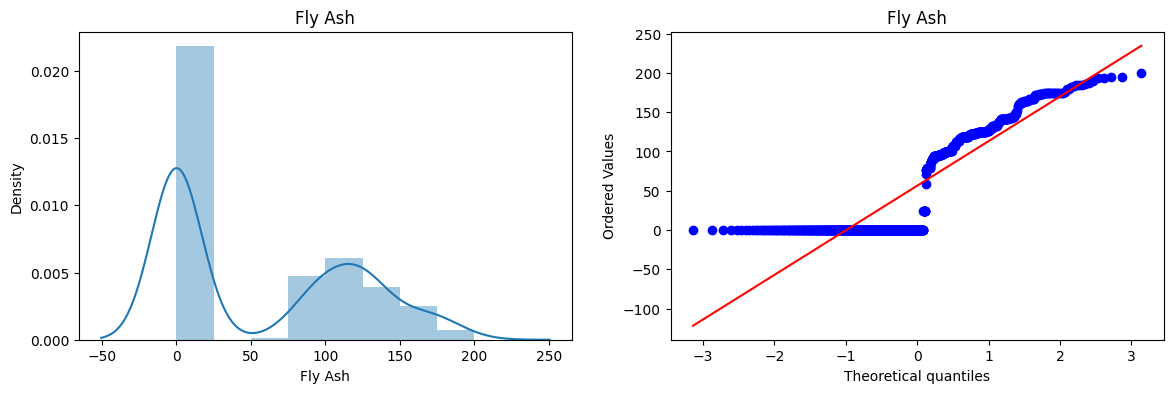

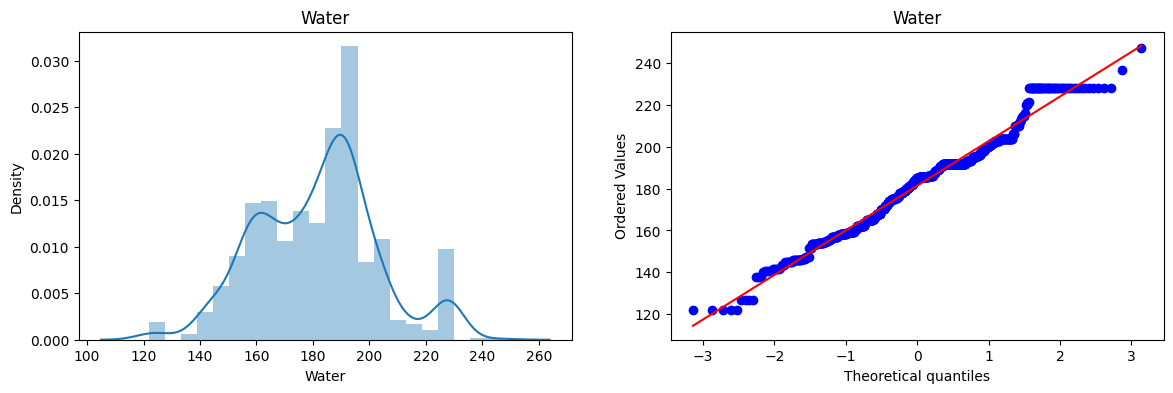

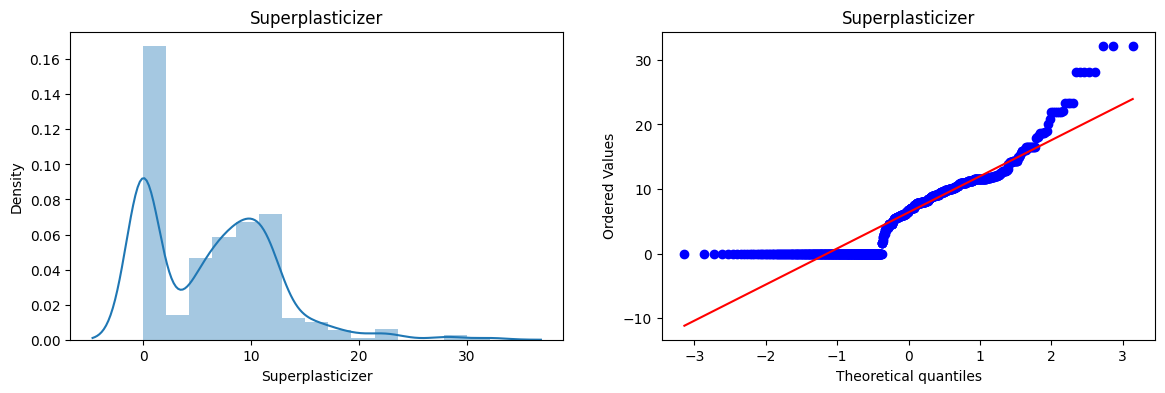

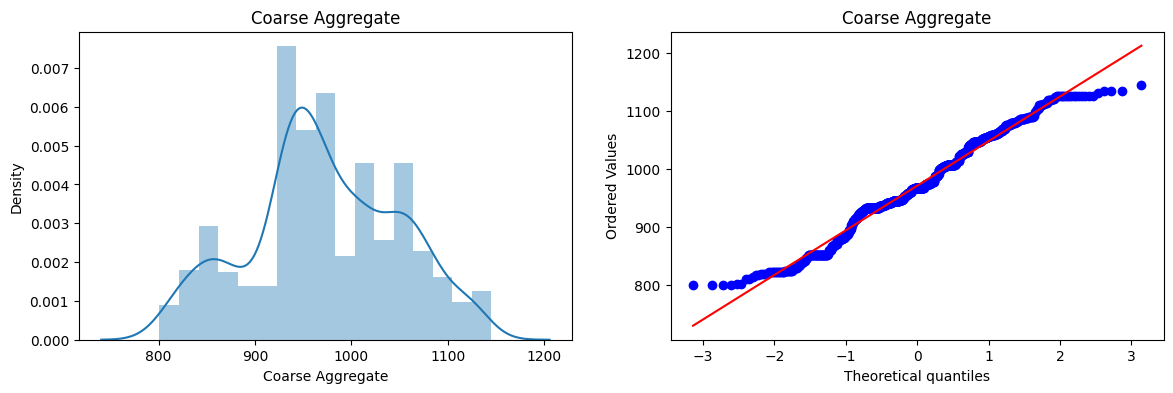

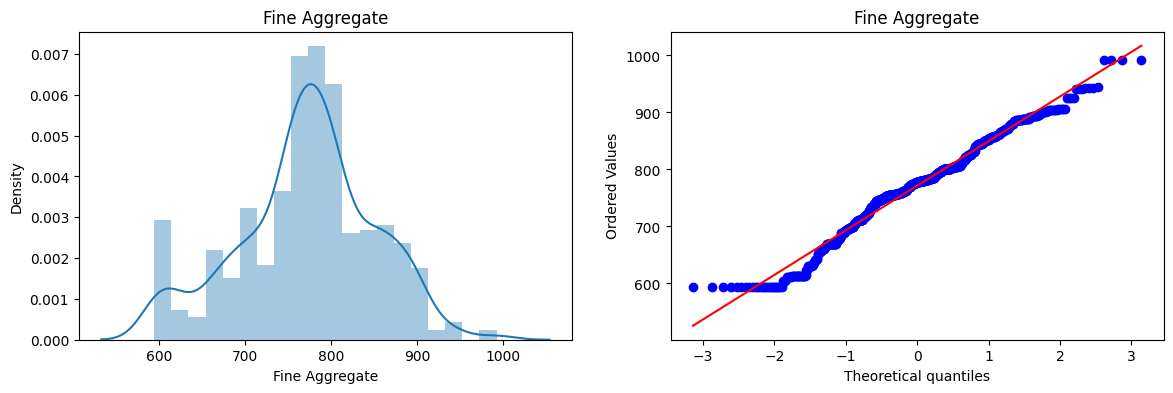

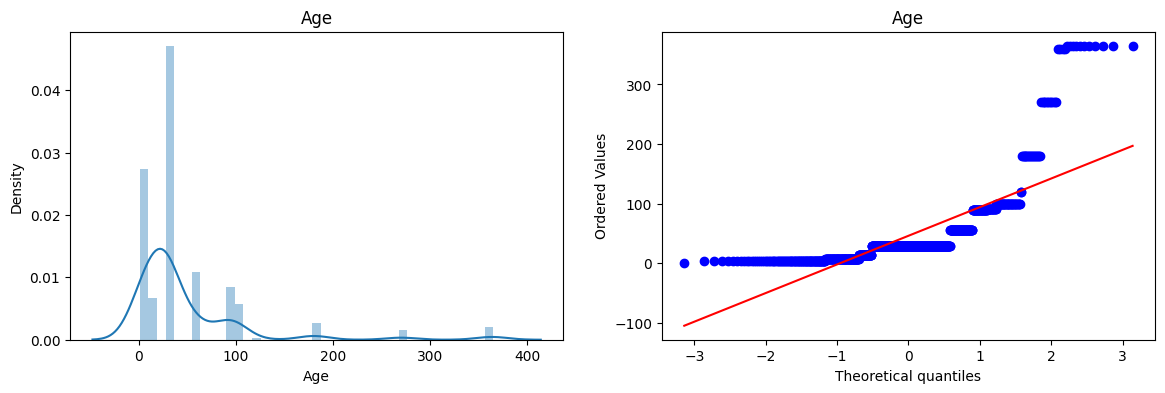

In [19]:
for column in x_train.columns:
    plt.figure(figsize = (14, 4))

    plt.subplot(121)
    sns.distplot(x_train[column])
    plt.title(column)

    plt.subplot(122)
    stats.probplot(x = x_train[column], dist = 'norm', plot = plt)
    plt.title(column)

# Applying PowerTransformer(Boxpox)

In [20]:
from sklearn.preprocessing import PowerTransformer

In [21]:
pt = PowerTransformer(method = 'box-cox')

# Here default method is 'yeo-johnson' and there's a parameter 'standardize' which is True bydefault. So we not need to explicitly scale the data.

In [22]:
x_train_trans = pt.fit_transform(x_train + 0.000001)
x_test_trans = pt.transform(x_test + 0.000001)

In [23]:
# Let's see which value the transformer selected for lambda.

data1 = {'Columns': x_train.columns, "box-cox lambda": pt.lambdas_}

In [24]:
pd.DataFrame(data1)

,Columns,box-cox lambda
0,Cement,0.171575
1,Blast Furnace Slag,0.032642
2,Fly Ash,-0.022238
3,Water,0.750949
4,Superplasticizer,0.111914
5,Coarse Aggregate,1.132517
6,Fine Aggregate,1.754408
7,Age,0.056568


# Applying LinearRegression on transformed data.

In [25]:
lr2 = LinearRegression()

lr2.fit(x_train_trans, y_train)

LinearRegression()

In [26]:
pred_trans_boxcox = lr2.predict(x_test_trans) 

In [27]:
r2_score(pred_trans_boxcox, y_test)

0.793975823659856

In [28]:
# Cross validation

cross_val_score(estimator = lr2, X = x_train_trans, y = y_train, scoring = 'r2', cv = 10).mean()

0.7899137912430844

# Ploting distplots and QQ plots after box-cox transformer.

In [29]:
# Creating DataFrames of transformed data

xtraintrans_df = pd.DataFrame(data = x_train_trans, columns = x_train.columns)

xtraintrans_df.sample(10)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
537,-1.910524,0.968417,-0.934003,1.030077,-1.346477,-0.173302,0.333537,-1.730181
753,-0.568993,-1.111898,1.058192,-1.030831,0.724417,0.471076,1.764162,0.696270
589,-0.121578,-1.111898,-0.934003,0.215053,-1.346477,1.833040,0.126759,-1.068534
681,-1.201812,-1.111898,1.089376,-0.815031,-1.346477,0.442404,1.725183,-0.503176
758,-0.181574,-1.111898,1.077387,-1.810856,0.815547,1.506042,0.344090,1.226515
297,-1.465459,-1.111898,1.085290,-1.093455,0.899896,0.395504,0.733328,0.084791
154,-0.740903,0.920454,-0.934003,0.505652,-1.346477,0.088605,0.672452,1.128865
394,1.044846,0.654309,1.052425,-1.141714,0.805784,-0.434479,0.938047,-1.068534
517,-1.354007,0.967697,-0.934003,0.551559,0.733870,-1.218604,1.257307,0.084791
294,-0.281973,1.006113,-0.934003,2.123485,-1.346477,-0.511913,-2.113894,0.084791


C:\Users\jugal\AppData\Local\Temp\ipykernel_12908\3572258778.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[column])
C:\Users\jugal\AppData\Local\Temp\ipykernel_12908\3572258778.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(xtraintrans_df[column])
C:\Users\jugal\AppData\Local\

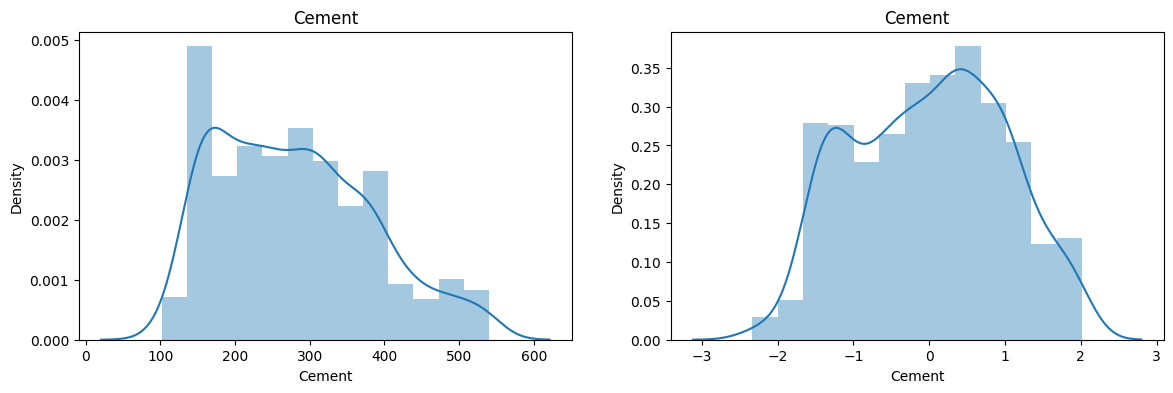

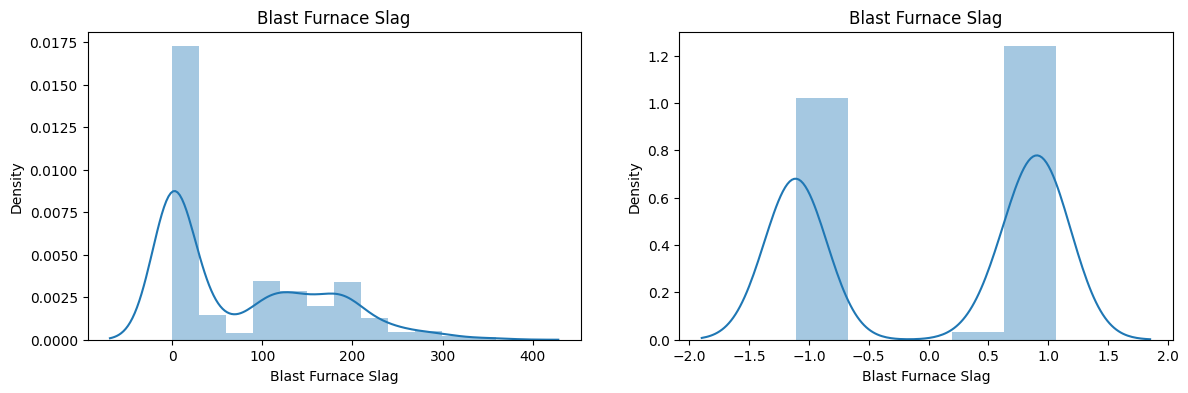

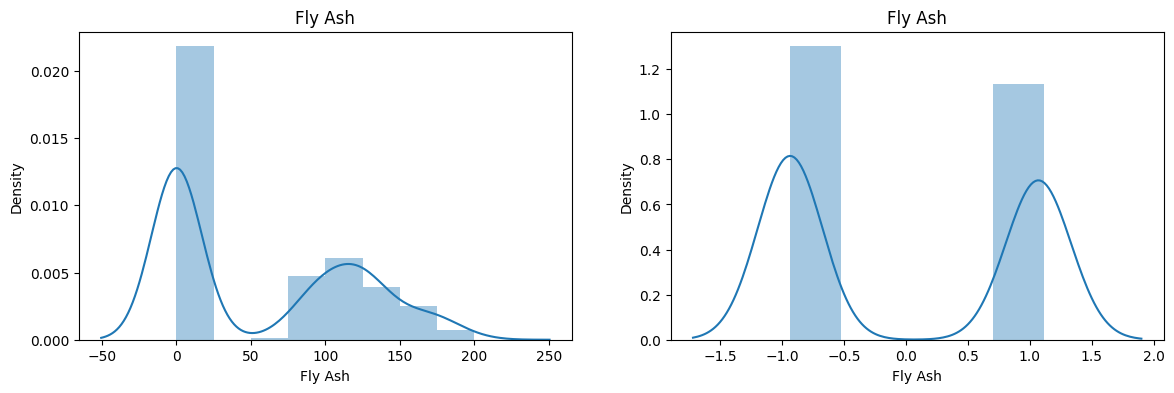

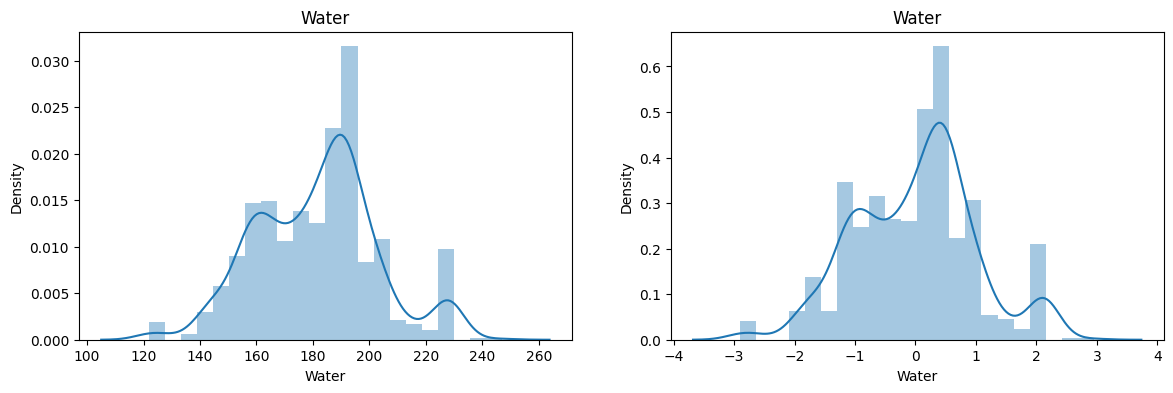

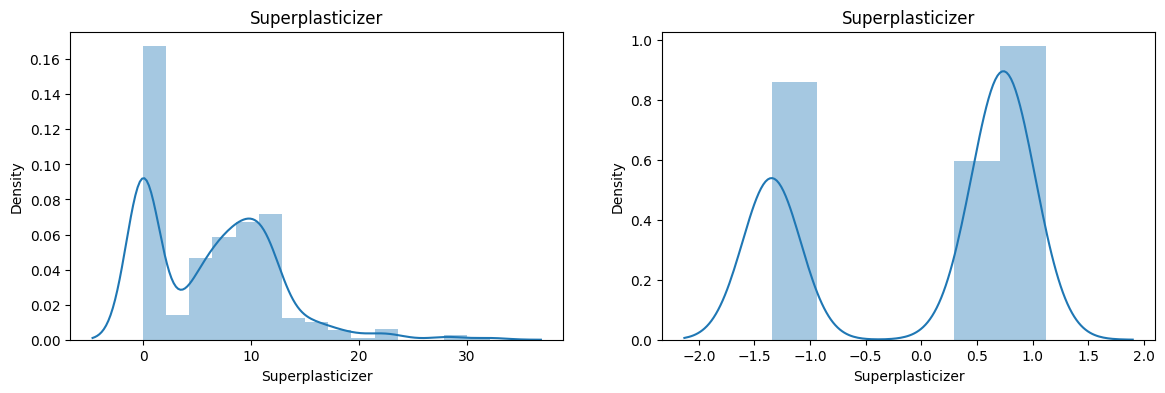

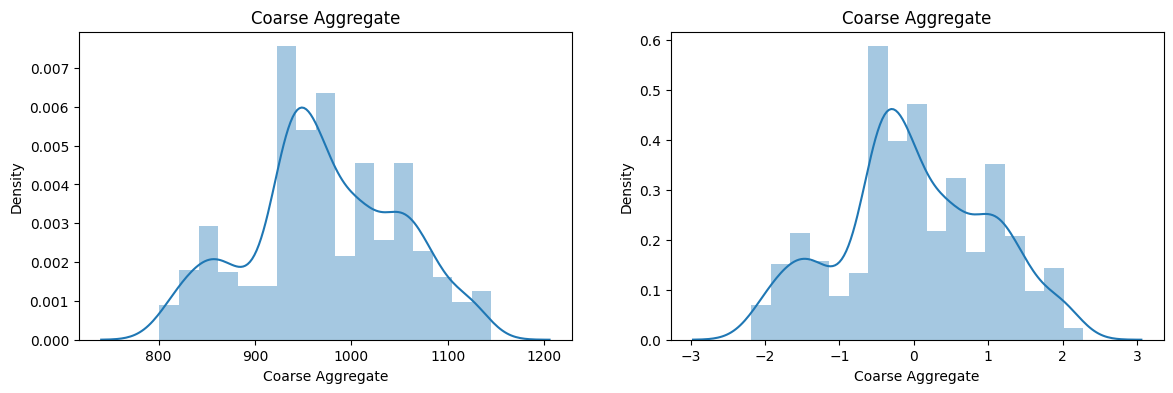

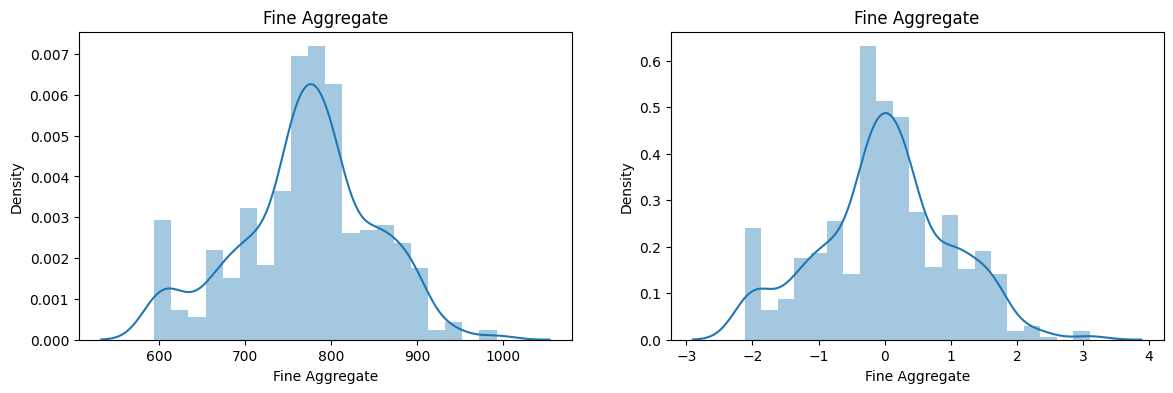

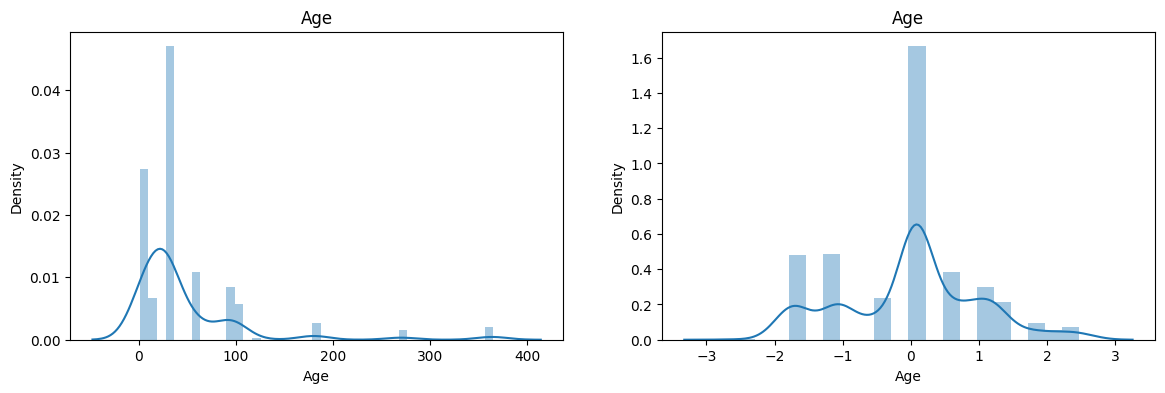

In [30]:
for column in xtraintrans_df.columns:
    plt.figure(figsize = (14, 4))

    plt.subplot(121)
    sns.distplot(x_train[column])
    plt.title(column)

    plt.subplot(122)
    sns.distplot(xtraintrans_df[column])
    plt.title(column)

# Applying yeo-johnson for transformer.

In [31]:
pt2 = PowerTransformer()    # bydefault method = 'yeo-johnson'

In [32]:
x_train_trans_yj = pt2.fit_transform(x_train)
x_test_trans_yj = pt2.transform(x_test)

In [33]:
lr3 = LinearRegression()

lr3.fit(x_train_trans_yj, y_train)

LinearRegression()

In [34]:
predict_yj = lr3.predict(x_test_trans_yj)

In [35]:
r2_score(predict_yj, y_test)

0.8030132362380888

In [36]:
cross_val_score(estimator = lr, X = x_train_trans_yj, y = y_train, cv = 10, scoring = 'r2').mean()

0.7929771678352118

In [42]:
# Let's see which values yeo-johnson selected for lambda

data2 = {"Columns": x_train.columns, "yeo-johnson lambda": pt2.lambdas_}

pd.DataFrame(data2)

,Columns,yeo-johnson lambda
0,Cement,0.168885
1,Blast Furnace Slag,0.034687
2,Fly Ash,-0.097061
3,Water,0.749513
4,Superplasticizer,0.306941
5,Coarse Aggregate,1.132739
6,Fine Aggregate,1.755440
7,Age,0.010500


# Ploting distplot and QQ plots after yeo-johnson transformer,


In [38]:
# Creating DataFrame of x_train_trans_yj.

xtrain_trans_yj_df = pd.DataFrame(data = x_train_trans_yj, columns = x_train.columns)

In [39]:
xtrain_trans_yj_df.sample(10)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
524,-1.078423,0.523436,1.200197,-0.767282,0.334727,0.450220,0.246780,-1.715220
815,-1.441110,1.209846,-0.931287,-0.246626,1.025991,-1.604168,1.607345,0.084368
482,-1.295226,1.214091,-0.931287,0.215058,-1.255978,0.899524,-0.506976,0.084368
723,1.451868,0.215862,0.942493,-0.901178,0.930066,-0.059296,-0.779415,0.084368
794,-1.449164,0.970207,1.050082,0.551566,0.262459,-1.026437,0.071020,0.084368
171,-0.493116,-1.078298,1.092607,-1.069362,0.900264,1.399456,0.265137,1.237288
624,-0.826186,1.301288,-0.931287,0.505659,-1.255978,-0.540292,-0.729801,-1.715220
455,-2.330350,1.013271,-0.931287,0.505659,-1.255978,-1.090540,2.328039,0.084368
756,-0.322974,-1.078298,1.003089,0.775660,0.038931,-0.318207,1.037291,0.706852
138,-1.433079,1.211394,-0.931287,-0.340673,0.959381,1.275893,-1.219704,0.084368


C:\Users\jugal\AppData\Local\Temp\ipykernel_12908\717698995.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[column])
C:\Users\jugal\AppData\Local\Temp\ipykernel_12908\717698995.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(xtrain_trans_yj_df[column])
C:\Users\jugal\AppData\Loca

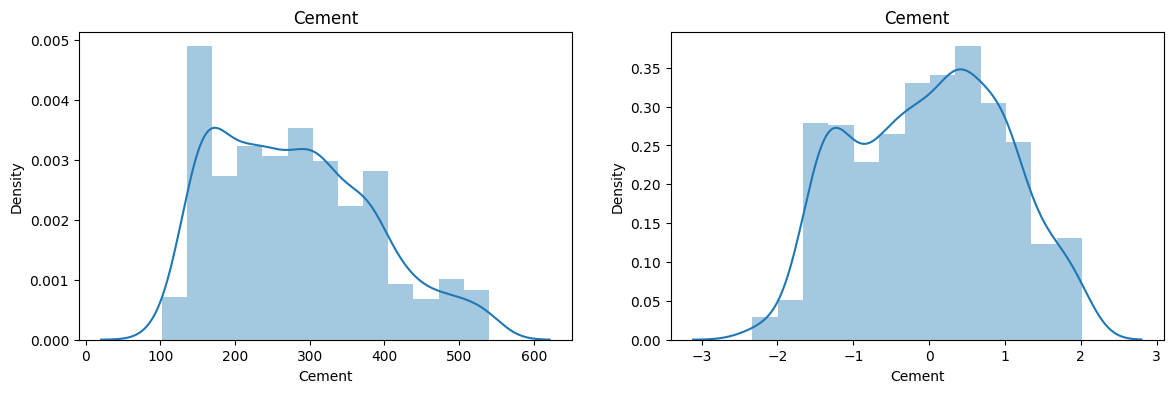

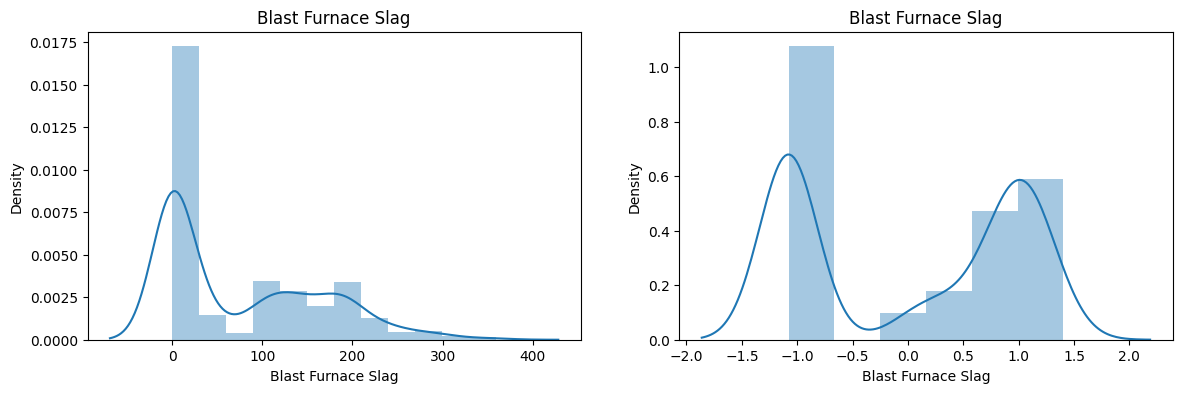

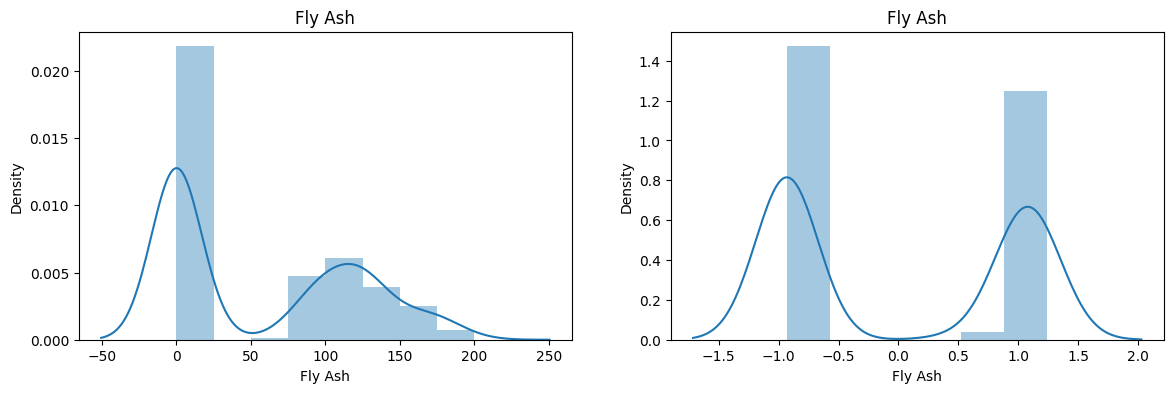

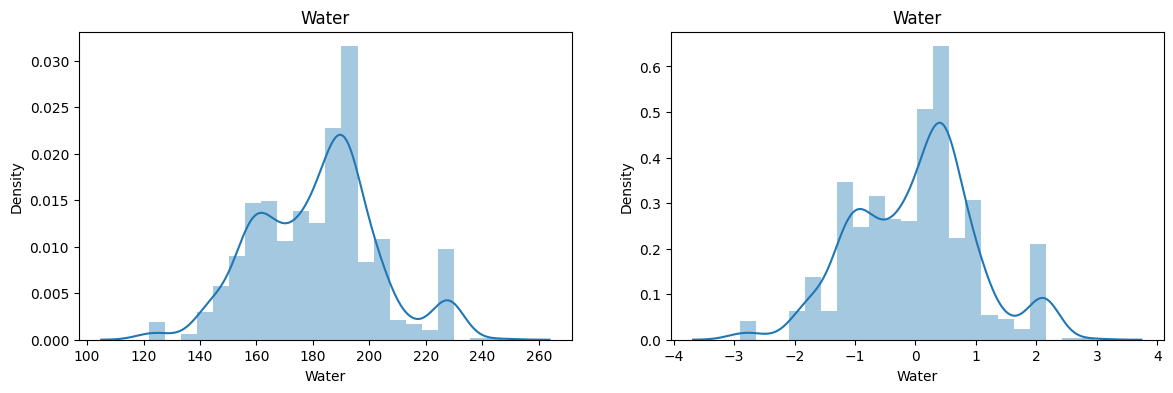

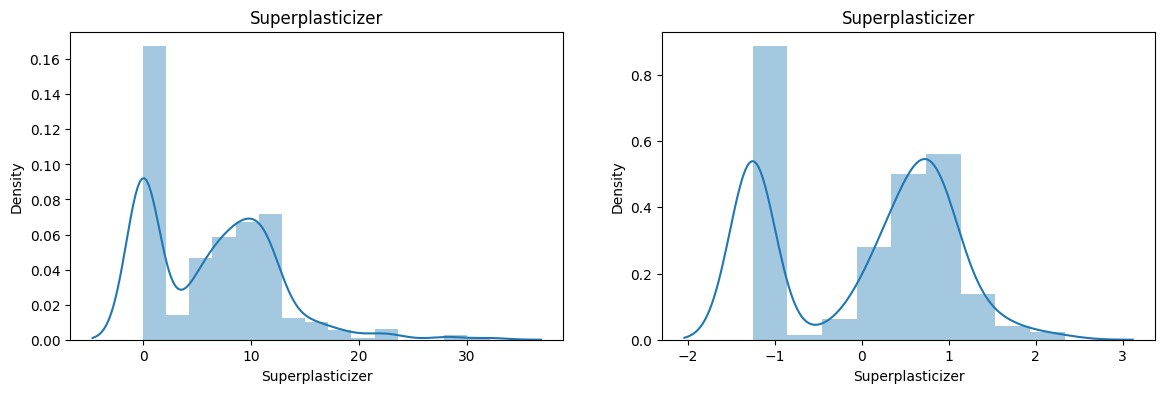

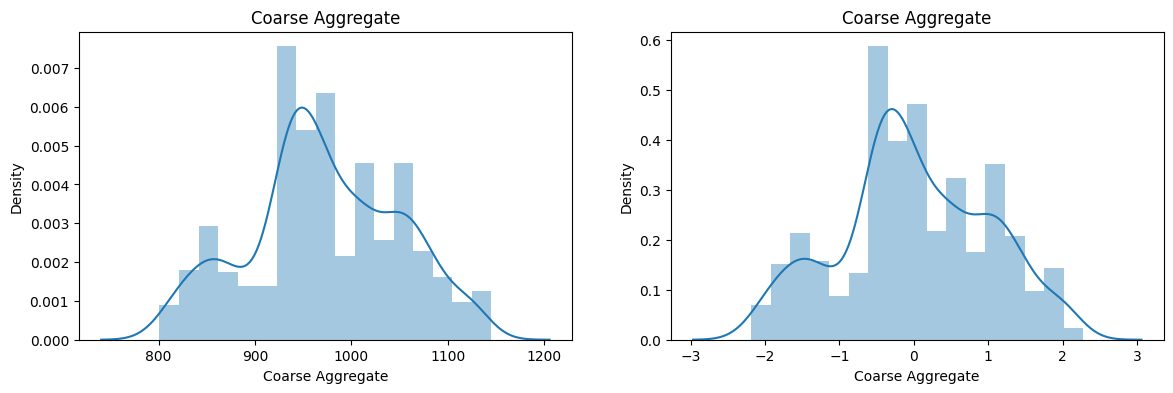

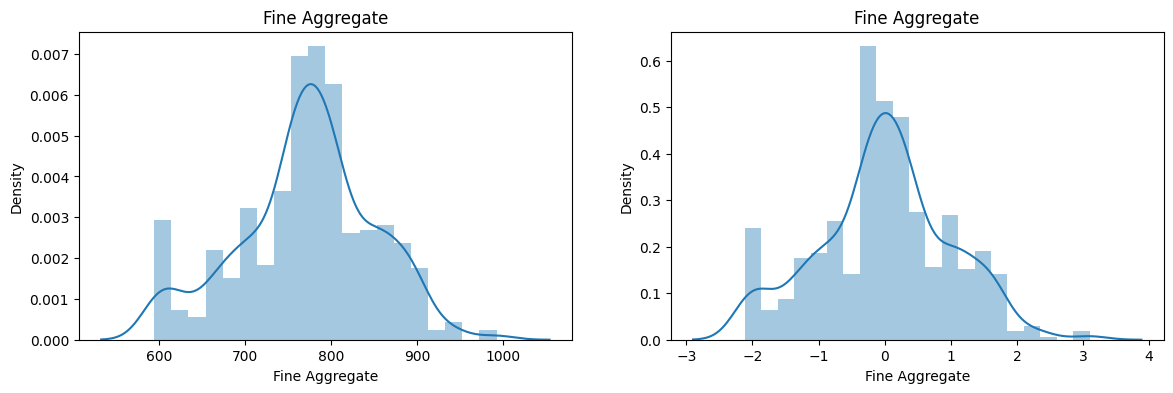

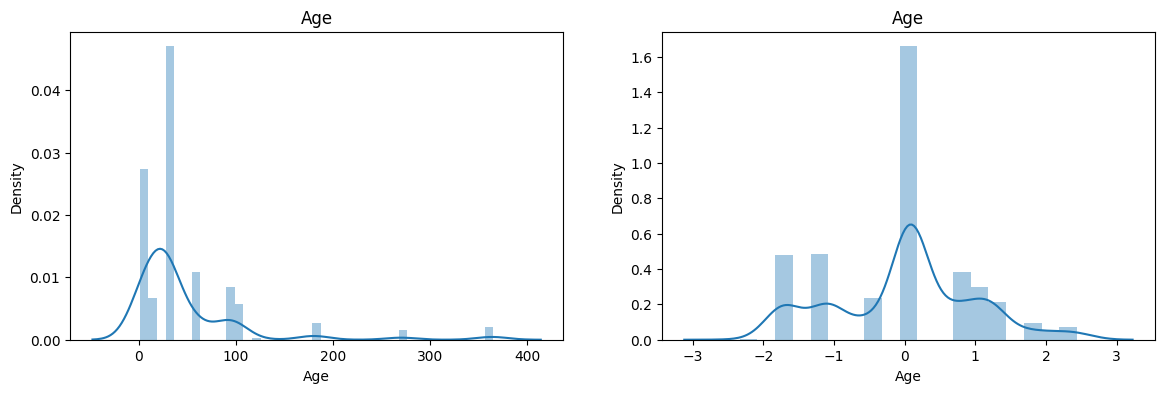

In [40]:
for column in xtrain_trans_yj_df:
    plt.figure(figsize = (14, 4))

    plt.subplot(121)
    sns.distplot(x_train[column])
    plt.title(column)

    plt.subplot(122)
    sns.distplot(xtrain_trans_yj_df[column])
    plt.title(column)

# Comparing lambdas selected by `box-cox` and `yeo-johnson`.

In [41]:
data3 = {'column': x_train.columns, 'box-cox lambda': pt.lambdas_, 'yeo-johnson lambda': pt2.lambdas_}

pd.DataFrame(data3)

,column,box-cox lambda,yeo-johnson lambda
0,Cement,0.171575,0.168885
1,Blast Furnace Slag,0.032642,0.034687
2,Fly Ash,-0.022238,-0.097061
3,Water,0.750949,0.749513
4,Superplasticizer,0.111914,0.306941
5,Coarse Aggregate,1.132517,1.132739
6,Fine Aggregate,1.754408,1.755440
7,Age,0.056568,0.010500


# Summary:

If you are working on any model which works well on data with normal distribution, like `Linear regression`, `Logistic regression` etc..., in that case, first see if your data is normally distributed or not(which mostly won't). 
* Then after identifying the distribution, apply `FunctionTransformer` or `PowerTransformer`.
* Is most of the cases, `PowerTrabsformer` performs better than the former one, but we can apply both and see the result.

# Next session: Day 32 Binning and Binarization(Discretiztion).